# Project 1 — ABSA UIT-ViSFD | SLP PyTorch (Kaggle)

**Mô hình chính:** TF-IDF + **Single-Layer Perceptron (SLP)**, một `nn.Linear(D, 40)` không có hidden layer, ReLU hay MLP. 40 logits được reshape thành 10 khía cạnh × 4 trạng thái.

**Quy trình:** Train/Dev/Test gốc → loại trùng chính xác Train so với Dev/Test → TF-IDF chỉ fit Train → SLP → weighted Cross-Entropy → Early Stopping theo Dev Pair F1 → Test cuối cùng.

**Metrics:** Aspect F1, Aspect–Sentiment Pair F1, Macro F1, Exact Match, State Accuracy; `tqdm` và 6 biểu đồ Train/Validation với **đầy đủ từng epoch**. 

> SLP sử dụng Softmax + Cross-Entropy về mặt toán học tương đương hồi quy logistic đa lớp. Mô hình này không có tầng ẩn. Không dùng MLP. Việc lọc trùng chính xác không loại trừ near-duplicates.


In [13]:
import os, re, random, copy, unicodedata
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tqdm import tqdm
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.feature_extraction.text import TfidfVectorizer

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ASPECTS=['SCREEN','CAMERA','FEATURES','BATTERY','PERFORMANCE','STORAGE','DESIGN','PRICE','GENERAL','SER&ACC']
STATES=['Absent','Negative','Neutral','Positive']
S2I={s:i for i,s in enumerate(STATES)}
print('Device:',DEVICE)


Device: cuda


## 1. Tìm dữ liệu và đọc nhãn

In [14]:
# Tự tìm bộ ba file trên Kaggle; nếu có nhiều bộ, sửa DATA_DIR thủ công.
roots=[Path('/kaggle/input'),Path('/kaggle/working'),Path('data/uit_visfd')]
found=[]
for root in roots:
    if root.exists():
        found += [p.parent for p in root.rglob('Train.csv') if (p.parent/'Dev.csv').exists() and (p.parent/'Test.csv').exists()]
if not found:
    raise FileNotFoundError('Chưa thấy Train.csv / Dev.csv / Test.csv. Hãy Add Input UIT-ViSFD trong Kaggle.')
DATA_DIR=found[0]
print('DATA_DIR:',DATA_DIR)
LABEL_RE=re.compile(r'\{([^{}#]+)#(Positive|Neutral|Negative)\}')
def parse_label(s):
    result={}
    for a,sent in LABEL_RE.findall(str(s)):
        if a not in ASPECTS: raise ValueError(f'Unknown aspect: {a}')
        if a in result and result[a]!=sent: raise ValueError('Conflicting label')
        result[a]=sent
    remaining=LABEL_RE.sub('',str(s)).replace('{OTHERS}','').replace(';','').strip()
    if remaining: raise ValueError(f'Unparsed label: {s}')
    return result

def load_csv(path):
    df=pd.read_csv(path,encoding='utf-8-sig')
    assert {'comment','label'}.issubset(df.columns),f'Missing columns in {path}'
    df['comment']=df['comment'].fillna('').astype(str)
    df['parsed']=df['label'].map(parse_label)
    return df
train_orig=load_csv(DATA_DIR/'Train.csv')
dev=load_csv(DATA_DIR/'Dev.csv')
test=load_csv(DATA_DIR/'Test.csv')
USE_SYNTHETIC=False # mặc định TẮT để tránh nguồn synthetic chưa kiểm chứng
syn_candidates=list(Path('/kaggle/input').rglob('Train_synthetic.csv')) if Path('/kaggle/input').exists() else []
if USE_SYNTHETIC:
    assert syn_candidates,'Không tìm thấy Train_synthetic.csv'
    train=pd.concat([train_orig,load_csv(syn_candidates[0])],ignore_index=True)
else: train=train_orig.copy()
print({'train':len(train),'dev':len(dev),'test':len(test),'synthetic_enabled':USE_SYNTHETIC})


DATA_DIR: /kaggle/input/datasets/tdluong1210/uit-visfd
{'train': 7786, 'dev': 1112, 'test': 2224, 'synthetic_enabled': False}


## 2. Kiểm tra trùng lặp giữa các split (không tự ý sửa split gốc)

In [15]:
# Kiểm tra và loại bỏ các mẫu Train trùng chính xác với Dev/Test.
# KHÔNG sửa Dev/Test, để giữ nguyên benchmark. Không dùng nhãn Dev/Test.
def norm(s):
    s=unicodedata.normalize('NFC',str(s)).lower()
    return ' '.join(s.split())

for name,df in [('Train',train),('Dev',dev),('Test',test)]:
    df['_norm']=df['comment'].map(norm)

def audit_duplicates():
    sets={k:set(df['_norm']) for k,df in [('Train',train),('Dev',dev),('Test',test)]}
    for a,b in [('Train','Dev'),('Train','Test'),('Dev','Test')]:
        print(f'Exact duplicate {a}/{b}:',len(sets[a]&sets[b]))

audit_duplicates()
blocked=set(dev['_norm'])|set(test['_norm'])
before=len(train)
train=train.loc[~train['_norm'].isin(blocked)].drop_duplicates(subset=['_norm'],keep='first').copy().reset_index(drop=True)
print(f'Removed {before-len(train)} Train rows (cross-split / intra-train exact duplicates)')
audit_duplicates()
if set(dev['_norm'])&set(test['_norm']):
    print('WARNING: Dev/Test overlap! Keep benchmark untouched, disclose this in report.')
print('Near-duplicate audit is separate; exact dedup does not eliminate paraphrases.')

Exact duplicate Train/Dev: 3
Exact duplicate Train/Test: 5
Exact duplicate Dev/Test: 0
Removed 10 Train rows (cross-split / intra-train exact duplicates)
Exact duplicate Train/Dev: 0
Exact duplicate Train/Test: 0
Exact duplicate Dev/Test: 0
Near-duplicate audit is separate; exact dedup does not eliminate paraphrases.


## 3. Mã hóa nhãn và TF-IDF (fit CHỈ Train)

In [16]:
def encode(df):
    return np.asarray([[S2I[lab.get(a,'Absent')] for a in ASPECTS] for lab in df.parsed],dtype=np.int64)
y_train,y_dev,y_test=map(encode,[train,dev,test])
MAX_FEATURES=30000  # nếu Kaggle thiếu RAM/GPU, giảm về 12000
vec=TfidfVectorizer(analyzer='char',ngram_range=(2,5),min_df=3,
                    max_features=MAX_FEATURES,sublinear_tf=True,dtype=np.float32)
X_train=vec.fit_transform(train.comment)  # fit CHỈ trên Train đã lọc
X_dev=vec.transform(dev.comment)
X_test=vec.transform(test.comment)
print('Shapes:',X_train.shape,X_dev.shape,X_test.shape)
print(pd.DataFrame({a:np.bincount(y_train[:,i],minlength=4)
                    for i,a in enumerate(ASPECTS)},index=STATES).T)

Shapes: (7776, 30000) (1112, 30000) (2224, 30000)
             Absent  Negative  Neutral  Positive
SCREEN         6827       379       56       514
CAMERA         5637       625      286      1228
FEATURES       5138      1656      198       784
BATTERY        4178      1227      348      2023
PERFORMANCE    3642      1496      391      2247
STORAGE        7685        21       11        59
DESIGN         6402       301       76       997
PRICE          5717       316     1136       607
GENERAL        2918       947      290      3621
SER&ACC        5782       487      107      1400


## 4. Metrics tự viết bằng NumPy (không dùng sklearn.metrics)

In [17]:
def evaluate_predictions(y_true,y_pred):
    assert y_true.shape==y_pred.shape
    true_present=y_true!=0; pred_present=y_pred!=0
    tp=np.logical_and(true_present,pred_present).sum()
    fp=np.logical_and(~true_present,pred_present).sum()
    fn=np.logical_and(true_present,~pred_present).sum()
    aspect_f1=2*tp/max(2*tp+fp+fn,1)
    tp_pair=np.logical_and(y_true==y_pred,true_present).sum()
    fp_pair=pred_present.sum()-tp_pair
    fn_pair=true_present.sum()-tp_pair
    pair_f1=2*tp_pair/max(2*tp_pair+fp_pair+fn_pair,1)
    per=[]
    for a in range(y_true.shape[1]):
        for s in [1,2,3]:
            t=y_true[:,a]==s; p=y_pred[:,a]==s
            z=np.logical_and(t,p).sum()
            per.append(2*z/max(t.sum()+p.sum(),1))
    return {'aspect_f1':float(aspect_f1),'pair_f1':float(pair_f1),
            'pair_macro_f1':float(np.mean(per)),
            'exact_match':float(np.all(y_true==y_pred,axis=1).mean()),
            'state_accuracy':float((y_true==y_pred).mean())}


## 5. DataLoader và mô hình Single-Layer Perceptron (SLP)


In [18]:
class CSRDataset(Dataset):
    def __init__(self,X,y): self.X=X.tocsr(); self.y=y
    def __len__(self): return self.X.shape[0]
    def __getitem__(self,i): return self.X[i],self.y[i]
def collate(batch):
    from scipy.sparse import vstack
    x=vstack([v[0] for v in batch]).toarray().astype(np.float32)
    y=np.stack([v[1] for v in batch])
    return torch.from_numpy(x),torch.from_numpy(y)
BATCH=128
train_loader=DataLoader(CSRDataset(X_train,y_train),batch_size=BATCH,shuffle=True,collate_fn=collate,num_workers=0)
dev_loader=DataLoader(CSRDataset(X_dev,y_dev),batch_size=BATCH,shuffle=False,collate_fn=collate,num_workers=0)
test_loader=DataLoader(CSRDataset(X_test,y_test),batch_size=BATCH,shuffle=False,collate_fn=collate,num_workers=0)
D=X_train.shape[1]
class ABSA_SLP(nn.Module):
    """Một tầng tuyến tính duy nhất: D -> 10*4 logits; không có hidden layer."""
    def __init__(self, d, num_aspects=10, num_classes=4):
        super().__init__()
        self.num_aspects=num_aspects
        self.num_classes=num_classes
        self.linear=nn.Linear(d,num_aspects*num_classes)

    def forward(self, x):
        return self.linear(x).reshape(-1,self.num_aspects,self.num_classes)

print('Input features:', D, '| Parameters:', sum(p.numel() for p in ABSA_SLP(D).parameters()))


Input features: 30000 | Parameters: 1200040


## 6. Training + tqdm + Early Stopping + metrics mỗi epoch

In [19]:
# Trọng số riêng theo từng khía cạnh, tính CHỈ từ nhãn Train.
# Capping tránh nhãn quá hiếm gây gradient không ổn định.
USE_CLASS_WEIGHTS=True
WEIGHT_POWER=0.5
MAX_CLASS_WEIGHT=4.0
counts=np.stack([np.bincount(y_train[:,j],minlength=4) for j in range(len(ASPECTS))])
weights=(counts.sum(axis=1,keepdims=True)/np.maximum(counts,1))**WEIGHT_POWER
weights=np.minimum(weights,MAX_CLASS_WEIGHT)
weights=weights/np.sum(weights*counts,axis=1,keepdims=True)*counts.sum(axis=1,keepdims=True)
CLASS_WEIGHTS=torch.tensor(weights,dtype=torch.float32,device=DEVICE)
print('Class weights (Train only):')
display(pd.DataFrame(weights,index=ASPECTS,columns=STATES).round(2))

def weighted_loss(logits,y):
    # loss cho từng aspect riêng biệt; 10 heads cùng đóng góp
    if not USE_CLASS_WEIGHTS:
        return nn.functional.cross_entropy(logits.reshape(-1,4),y.reshape(-1))
    return torch.stack([
        nn.functional.cross_entropy(logits[:,j,:],y[:,j],weight=CLASS_WEIGHTS[j])
        for j in range(len(ASPECTS))
    ]).mean()

def run_epoch(model,loader,optimizer=None,desc=''):
    training=optimizer is not None
    model.train(training)
    total_loss=0.;n=0;all_true=[];all_pred=[]
    for x,y in tqdm(loader,desc=desc,leave=False):
        x=x.to(DEVICE);y=y.to(DEVICE)
        if training:optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits=model(x)
            loss=weighted_loss(logits,y)
            if training:loss.backward();optimizer.step()
        total_loss+=loss.detach().item()*len(y);n+=len(y)
        all_true.append(y.cpu().numpy())
        all_pred.append(logits.argmax(-1).detach().cpu().numpy())
    scores=evaluate_predictions(np.concatenate(all_true),np.concatenate(all_pred))
    return {'loss':total_loss/n,**scores}

def fit_model(model,name,epochs=35,lr=0.002,patience=7):
    model=model.to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=1e-4)
    history=[];best=-1.;stale=0;best_state=None;best_epoch=0
    for epoch in range(1,epochs+1):
        tr=run_epoch(model,train_loader,optimizer,f'{name} Train {epoch}/{epochs}')
        va=run_epoch(model,dev_loader,None,f'{name} Dev {epoch}/{epochs}')
        row={'epoch':epoch,**{'train_'+k:v for k,v in tr.items()},
             **{'val_'+k:v for k,v in va.items()}}
        history.append(row)
        print(f'{name} epoch {epoch:02d} | train loss {tr["loss"]:.4f} | '
              f'val loss {va["loss"]:.4f} | val aspect F1 {va["aspect_f1"]:.4f} | '
              f'val pair F1 {va["pair_f1"]:.4f} | val macro F1 {va["pair_macro_f1"]:.4f}')
        if va['pair_f1']>best+1e-5:
            best=va['pair_f1'];best_epoch=epoch
            best_state=copy.deepcopy({k:v.detach().cpu() for k,v in model.state_dict().items()})
            stale=0
        else:stale+=1
        if stale>=patience:
            print(f'Early stopping; best epoch {best_epoch}')
            break
    model.load_state_dict(best_state)
    return model,pd.DataFrame(history),best_epoch

Class weights (Train only):


,Absent,Negative,Neutral,Positive
SCREEN,0.75,2.82,2.82,2.74
CAMERA,0.70,2.10,2.38,1.50
FEATURES,0.73,1.28,2.36,1.86
BATTERY,0.75,1.38,2.20,1.08
PERFORMANCE,0.78,1.22,2.15,1.00
STORAGE,0.97,3.84,3.84,3.84
DESIGN,0.76,2.74,2.74,1.91
PRICE,0.69,2.38,1.56,2.13
GENERAL,0.91,1.60,2.23,0.82
SER&ACC,0.73,2.51,2.51,1.48


## 7. Huấn luyện SLP (không có MLP)


In [20]:
EPOCHS=35
slp,history_slp,best_slp=fit_model(ABSA_SLP(D),'ABSA-SLP',epochs=EPOCHS,lr=0.01)
print('Best epoch:',best_slp)


ABSA-SLP epoch 01 | train loss 0.8832 | val loss 0.7086 | val aspect F1 0.7631 | val pair F1 0.6632 | val macro F1 0.3725


ABSA-SLP epoch 02 | train loss 0.5091 | val loss 0.6262 | val aspect F1 0.7913 | val pair F1 0.6890 | val macro F1 0.4331


ABSA-SLP epoch 03 | train loss 0.3619 | val loss 0.5983 | val aspect F1 0.8038 | val pair F1 0.6998 | val macro F1 0.4451


ABSA-SLP epoch 04 | train loss 0.2749 | val loss 0.5916 | val aspect F1 0.8108 | val pair F1 0.7080 | val macro F1 0.4536


ABSA-SLP epoch 05 | train loss 0.2184 | val loss 0.5904 | val aspect F1 0.8150 | val pair F1 0.7096 | val macro F1 0.4555


ABSA-SLP epoch 06 | train loss 0.1789 | val loss 0.5933 | val aspect F1 0.8182 | val pair F1 0.7121 | val macro F1 0.4574


... (4 outputs left out)

ABSA-SLP epoch 11 | train loss 0.0845 | val loss 0.6343 | val aspect F1 0.8149 | val pair F1 0.7068 | val macro F1 0.4532


ABSA-SLP epoch 12 | train loss 0.0752 | val loss 0.6445 | val aspect F1 0.8141 | val pair F1 0.7051 | val macro F1 0.4502


ABSA-SLP epoch 13 | train loss 0.0673 | val loss 0.6526 | val aspect F1 0.8158 | val pair F1 0.7077 | val macro F1 0.4519


ABSA-SLP epoch 14 | train loss 0.0605 | val loss 0.6634 | val aspect F1 0.8138 | val pair F1 0.7049 | val macro F1 0.4508
Early stopping; best epoch 7
Best epoch: 7


## 8. Biểu đồ: HIỂN THỊ ĐỦ TẤT CẢ EPOCH TRÊN TRỤC X

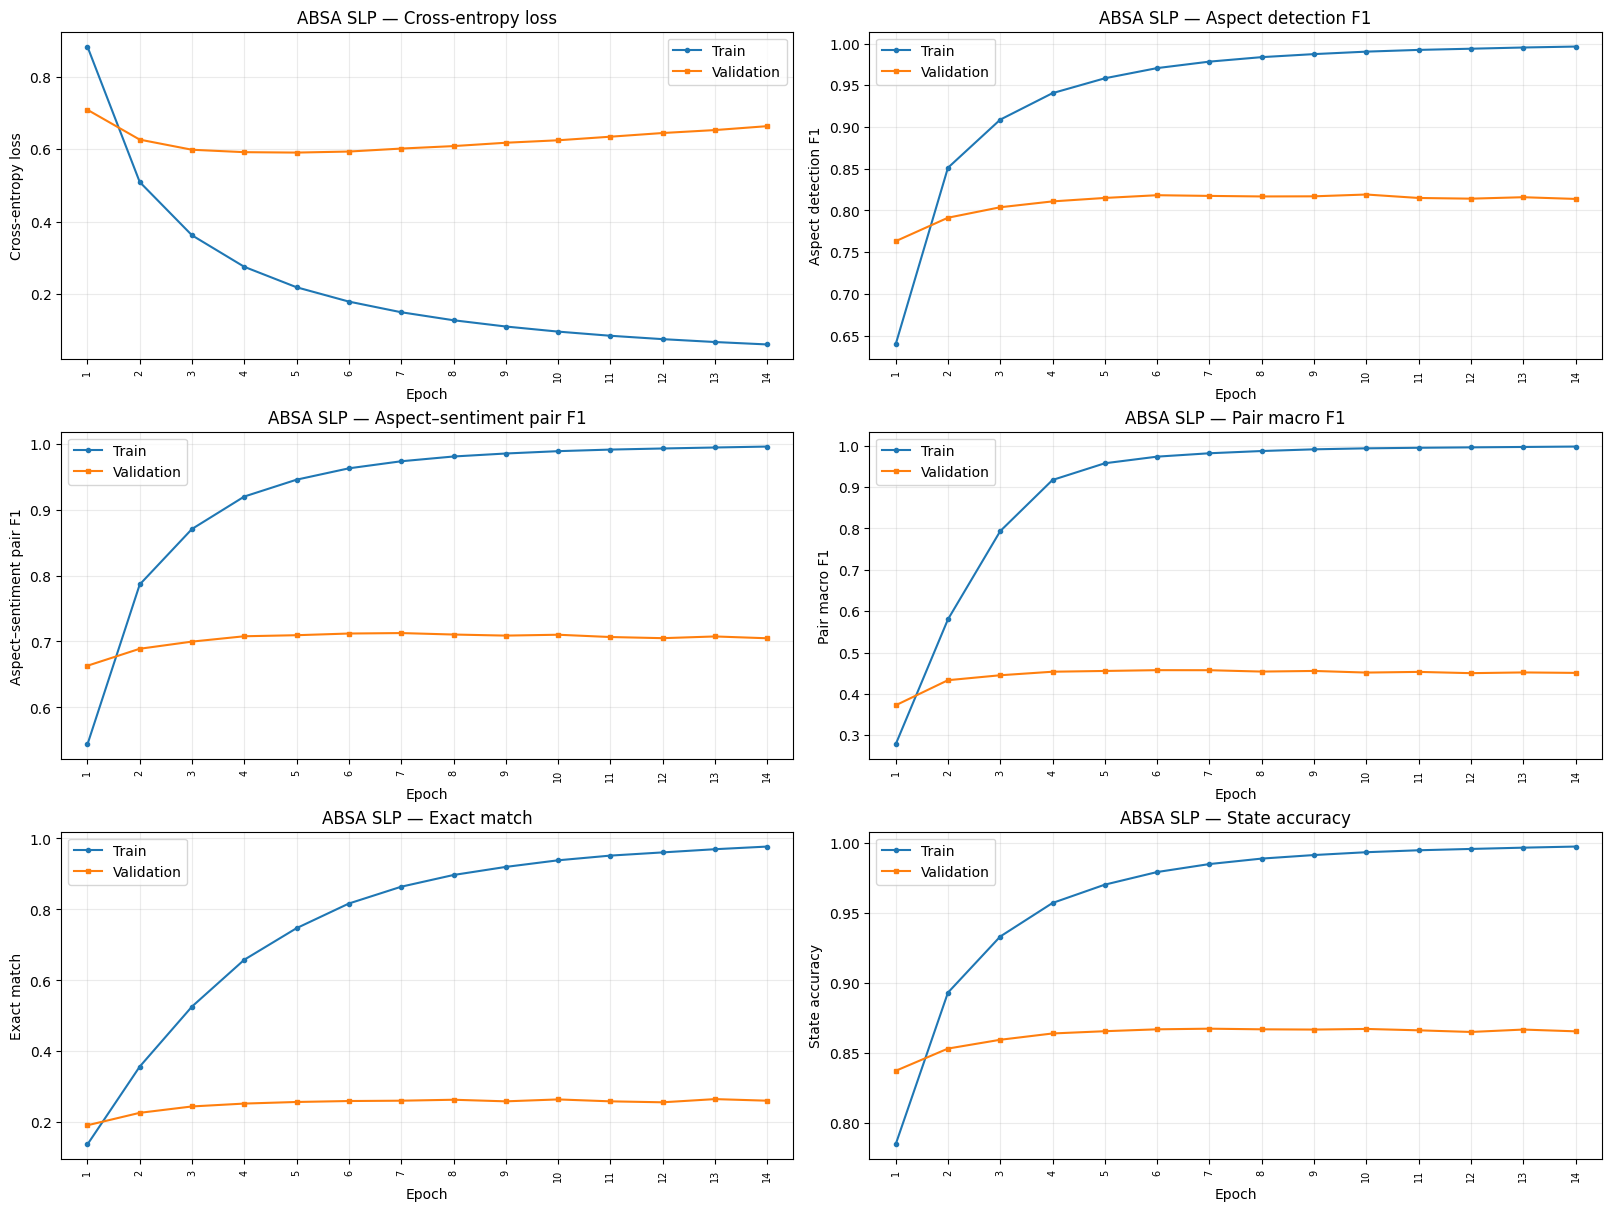

In [21]:
def plot_history(history,name):
    metrics=[('loss','Cross-entropy loss'),('aspect_f1','Aspect detection F1'),
             ('pair_f1','Aspect–sentiment pair F1'),('pair_macro_f1','Pair macro F1'),
             ('exact_match','Exact match'),('state_accuracy','State accuracy')]
    epochs=history['epoch'].to_numpy()
    fig,axes=plt.subplots(3,2,figsize=(16,12),constrained_layout=True)
    for ax,(key,label) in zip(axes.flat,metrics):
        ax.plot(epochs,history['train_'+key],marker='o',markersize=3,label='Train')
        ax.plot(epochs,history['val_'+key],marker='s',markersize=3,label='Validation')
        ax.set_title(f'{name} — {label}');ax.set_xlabel('Epoch');ax.set_ylabel(label)
        ax.set_xticks(epochs)  # QUAN TRỌNG: 1, 2, ..., TẤT CẢ epoch đã chạy
        ax.set_xlim(0.5,len(epochs)+0.5)
        ax.tick_params(axis='x',labelrotation=90,labelsize=7)
        ax.grid(alpha=0.25);ax.legend()
    plt.show()
plot_history(history_slp,'ABSA SLP')


## 9. Đánh giá Dev và Test (không dùng Test để chọn hyperparameters)


In [22]:
def predict_loader(model,loader):
    model.eval();out=[]
    with torch.no_grad():
        for x,_ in tqdm(loader,desc='Predict',leave=False):
            out.append(model(x.to(DEVICE)).argmax(-1).cpu().numpy())
    return np.concatenate(out)
print('DEV scores:')
val_pred=predict_loader(slp,dev_loader)
display(pd.DataFrame([evaluate_predictions(y_dev,val_pred)],index=['SLP']).round(4))

# Chỉ đánh giá Test sau khi hoàn thành lựa chọn cấu hình bằng Dev.
chosen=slp
best_name='SLP'
pred_test=predict_loader(chosen,test_loader)
print('TEST scores:')
display(pd.DataFrame([evaluate_predictions(y_test,pred_test)],index=['SLP']).round(4))


DEV scores:


,aspect_f1,pair_f1,pair_macro_f1,exact_match,state_accuracy
SLP,0.8174,0.7128,0.4573,0.2608,0.8675


TEST scores:


,aspect_f1,pair_f1,pair_macro_f1,exact_match,state_accuracy
SLP,0.8059,0.7007,0.4484,0.2491,0.8595


## 10. Confusion matrix theo khía cạnh và ví dụ dự đoán

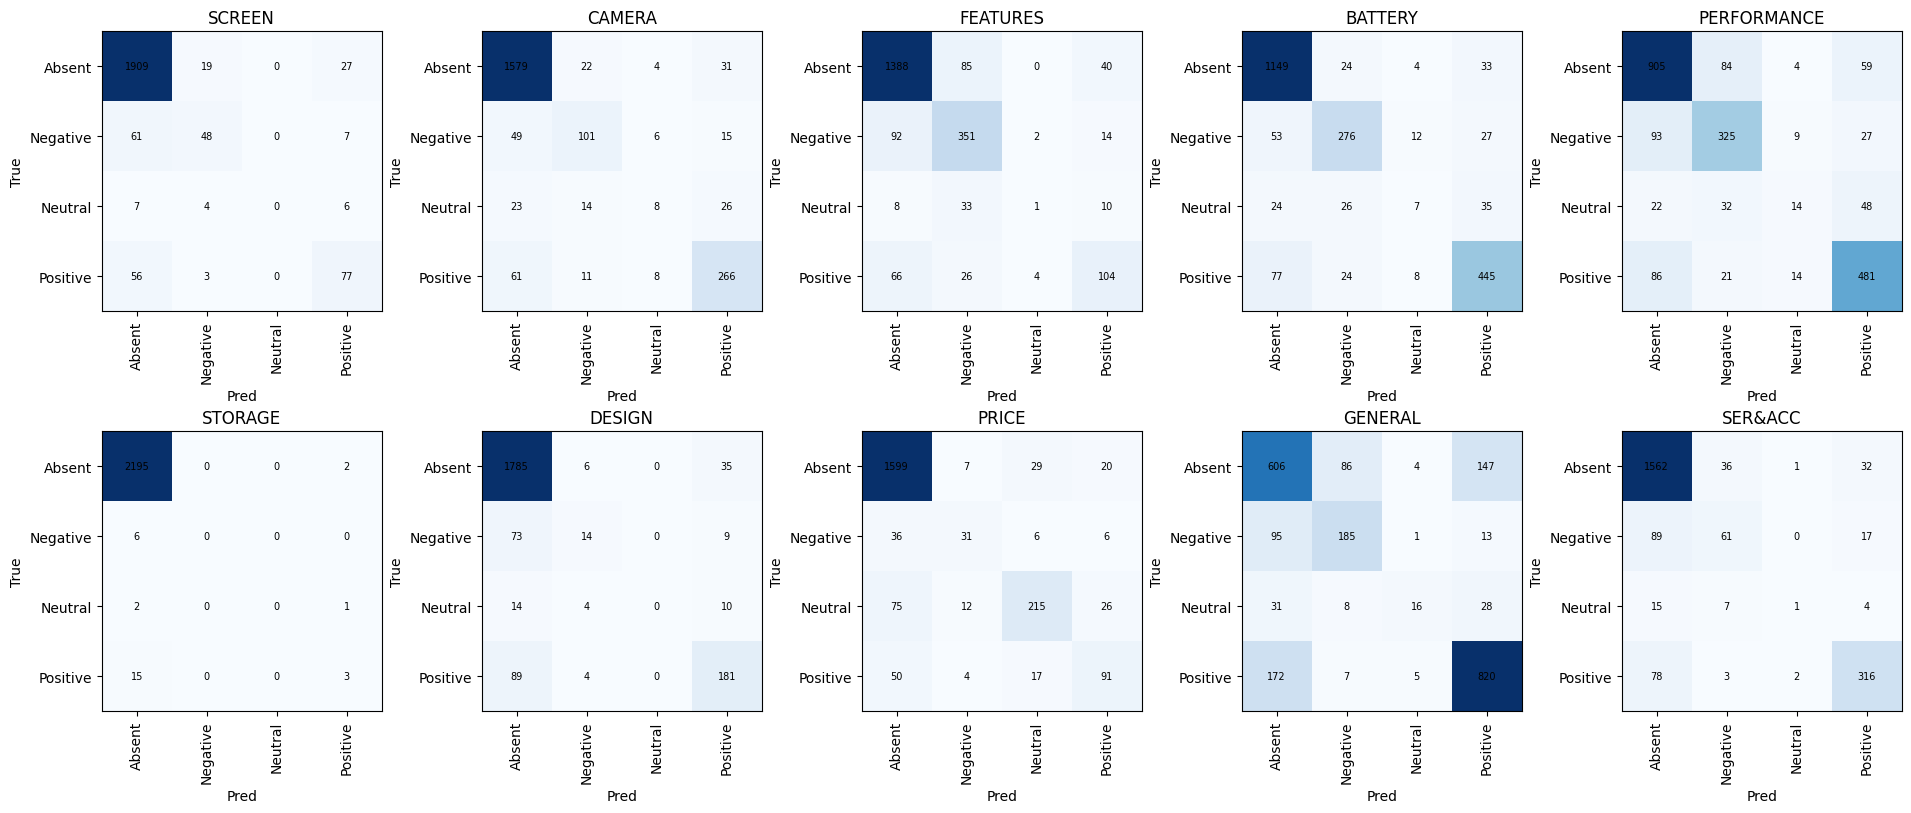

{'SCREEN': 'Neutral', 'CAMERA': 'Positive', 'BATTERY': 'Positive', 'GENERAL': 'Positive'}


In [24]:
chosen=slp
fig,axes=plt.subplots(2,5,figsize=(19,8),constrained_layout=True)
for j,(a,ax) in enumerate(zip(ASPECTS,axes.flat)):
    cm=np.zeros((4,4),dtype=int)
    for t,p in zip(y_test[:,j],pred_test[:,j]):cm[t,p]+=1
    ax.imshow(cm,cmap='Blues')
    for r in range(4):
        for c in range(4):ax.text(c,r,str(cm[r,c]),ha='center',va='center',fontsize=7)
    ax.set_xticks(range(4),STATES,rotation=90);ax.set_yticks(range(4),STATES)
    ax.set_title(a);ax.set_xlabel('Pred');ax.set_ylabel('True')
plt.show()

def predict_comment(comment):
    x=torch.from_numpy(vec.transform([comment]).toarray().astype(np.float32)).to(DEVICE)
    chosen.eval()
    with torch.no_grad(): ids=chosen(x).argmax(-1).cpu().numpy()[0]
    return {a:STATES[int(ids[i])] for i,a in enumerate(ASPECTS) if ids[i]!=0}
print(predict_comment('Pin rất tốt, camera chụp đẹp nhưng màn hình khá tệ.'))


## 11. Lưu lịch sử và checkpoint

In [25]:
OUT=Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
history_slp.to_csv(OUT/'absa_slp_history.csv',index=False)
torch.save({'model':best_name,'state_dict':{k:v.cpu() for k,v in chosen.state_dict().items()},
            'features':D,'aspects':ASPECTS,'states':STATES},OUT/'absa_best_model.pt')
import pickle
with open(OUT/'absa_tfidf.pkl','wb') as f:pickle.dump(vec,f)
print('Saved to',OUT)


Saved to /kaggle/working


### Ghi chú khi báo cáo

- **SLP:** 1 `nn.Linear(D, 40)`, không có hidden layer; 10 nhóm Softmax, mỗi nhóm 4 trạng thái `Absent`, `Negative`, `Neutral`, `Positive`.
- **Loss:** Class-weighted Cross-Entropy theo từng khía cạnh, trọng số chỉ tính từ Train.
- **TF-IDF:** `fit_transform` Train, `transform` Dev/Test; không fit trên Dev/Test.
- **Data leakage:** loại mẫu Train trùng nội dung chính xác với Dev/Test; vẫn cần kiểm tra near-duplicate trước khi công bố kết quả.
- **Early stopping:** theo Dev Pair F1; biểu đồ có tick cho từng epoch đã chạy.
- **Test:** dùng để đánh giá cuối cùng, không điều chỉnh hyperparameters theo Test.
- **Độ khó:** Mô hình SLP đơn giản, phù hợp kiến thức một tầng; về toán học là hồi quy logistic đa lớp cho mỗi khía cạnh.
